# Titanic - Wie kann anhand verschiedener Merkmale herausgefunden werden, ob ein Passagier überlebt?

Wir wollen eine oder mehrere Eigenschaften angeben und dann die Überlebenschancen des jeweiligen Passagiers berechnen können. Hier einmal Step für Step:

1. Librarys importieren:

In [142]:
## Imports
import joblibimport pandas as pd ##Tabellen: df als DataFrame
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

2. Nullstellen streichen und unwichtige Kategorien entfernen:

In [143]:
##Datensatz ohne Nullstellen
##alt: Wenn Output nicht np.int64(0) ist, gibt es irgendwo Nullstellen, die sollten aber in einer Tabelle aufgezeigt werden dass man ca weiß wo man suchen muss

df = pd.read_csv("Titanic-Dataset.csv") ##Datensatz wird zugewiesen

df_clean = df.copy() #Kopie damit das alte nicht gelöscht wirddf_clean= df.drop(columns=["Cabin"])## wird rausgenommen



print(df_clean["Age"].isnull().sum())

df_clean = df_clean.dropna(subset = ["Age"])# fehlen nicht dramatisch viele Einträge, Nullstellen kann man streichen

print(df_clean["Age"].isnull().sum())


df_clean = df_clean.drop(columns=["Cabin"])#zu viele fehlende einträge


df_clean = df_clean.drop(columns=["Embarked"]) #sehr unwichtig wo sie eingestiegen sind, da das ja
df_clean = df_clean.drop(columns=["Name"]) #brauchen wir nicht essenziel, ich bezweifle dass z.b. ein Thomas schneller schwimmt als ein Guenther
df_clean = df_clean.drop(columns=["PassengerId"])#brauchen wir nicht da wir nur wahrscheinlichkeiten errechnen wollen und nicht den Datensatz nach Daten von bestimmten personen durchsuchen wollen 
df_clean = df_clean.drop(columns=["Ticket"])#gleiche situtation wie bei den beiden oberen


print("Nullwerte:", df_clean.isnull().sum())



177
0
Nullwerte: Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
dtype: int64


3. Falschwerte:

In [144]:
## Evtl Falschwerte: einfach nur zur demonstration anzeigen lassen, da man in Kaggle sich Graphen anzeigeb lassen kann und bei keinem steht irgendeine Value unter 0 -> auch andersherum passt es von den Daten
df_clean[df_clean["Fare"] == 0]
df_clean[df_clean["Age"] == -1]

df_clean = df_clean[df_clean["Fare"] <= 500]


4. Nach doppelten Werten checken: 

In [145]:
##Check for Duplicates
print("Duplicates:", df_clean.duplicated().sum())

Duplicates: 40


5. String in Integer umwandeln:

In [146]:
df_clean["Sex"] = df_clean["Sex"].map({'male': 0,'female': 1}) ## werte werden ersetzt: für male 0 für female 1
df_clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
0,0,3,0,22.0,1,0,7.2500
1,1,1,1,38.0,1,0,71.2833
2,1,3,1,26.0,0,0,7.9250
3,1,1,1,35.0,1,0,53.1000
4,0,3,0,35.0,0,0,8.0500


7. Zusammenhänge: Wie unwichtig sind die jeweiligen Kategorien für das Überleben des Passagieres?
von oben (unwichtig)
nach unten (sehr wichtig)

In [147]:
##wie wichtig sind die Nummern auf einer Skala von 1 (Sehr wichtig) bis -1 (extrem unwichtig)
df_clean.corr(numeric_only=True)["Survived"].sort_values(ascending=True)

Pclass     -0.354847
Age        -0.079472
SibSp      -0.014598
Parch       0.094258
Fare        0.275122
Sex         0.541935
Survived    1.000000
Name: Survived, dtype: float64

8. Heatmap zur Veranschaulichung:

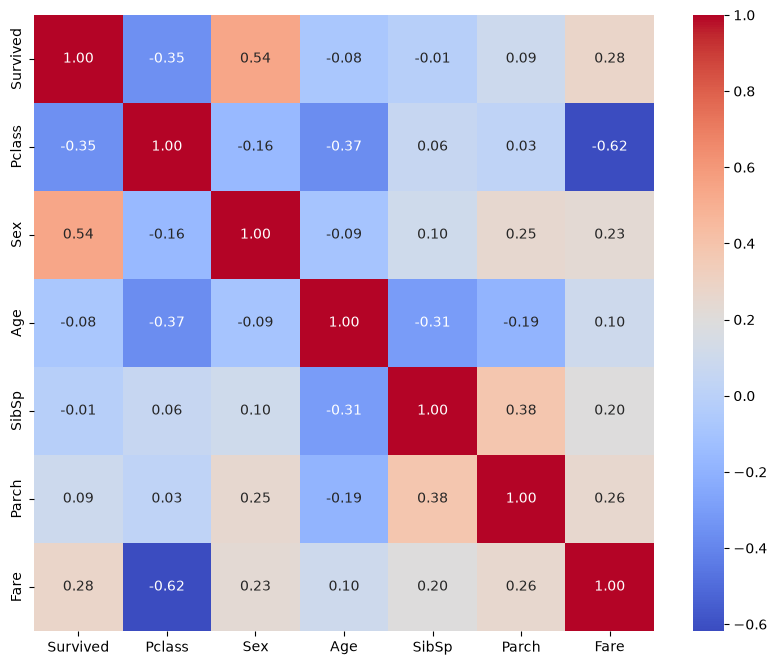

In [148]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean.corr(numeric_only=True), annot=True, fmt=".2f",cmap="coolwarm")
plt.show()

* Hier sehen wir einmal, wie die Spalten miteinander zusammenhängen. 
* Die Spalte, die für uns am wichtigsten ist, ist natürlich "Survived". Dort kann man sich genau anschauen wie wichtig z.B. das Geschlecht oder der Ticketpreis fürs Überleben sind 
* Ticketpreis wahrscheinlich insofern, da  Gäste vermutlich zuerst gerettet wurden und/oder da sich die Kabinen der Gäste weit oder weniger weit entfernt von den Rettungsbooten bwfinden.

# Überlebensrate nach Geschlecht

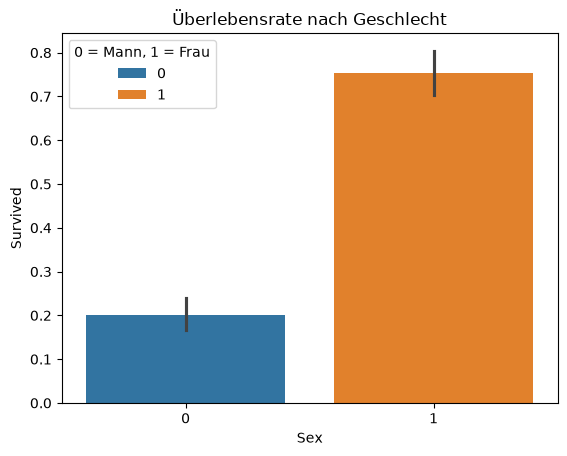

In [149]:
df_clean.groupby("Sex")["Survived"].mean() ##Gruppierung in Überlebte Frauen u. Männer
sns.barplot(data=df_clean, x="Sex", y="Survived", hue="Sex")
plt.legend(title= "0 = Mann, 1 = Frau", loc= "upper left")
plt.title("Überlebensrate nach Geschlecht")
plt.show()

Wir können aus dem Diagramm entnehmen, dass die Wahrscheinlichkeit als Frau zu überleben, 4 mal höher ist, wie die Chancen als Mann zu überleben!
Die Überlebensquote bei Frauen steht bei 80% und die bei Männern bei 20%.

# Verhältniss: Alter zu Lebensstatus

/var/folders/46/53bsc3x97ll5rz9vb0vggwnc0000gn/T/ipykernel_12021/772461424.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title= "0 = Nicht überlebt 1 = überlebt", loc="upper right")


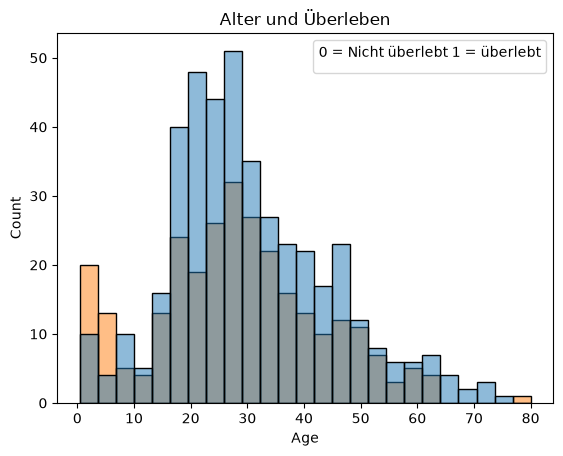

In [150]:
sns.histplot(data=df_clean, x="Age", hue="Survived", bins=25)
plt.title("Alter und Überleben")
plt.legend(title= "0 = Nicht überlebt 1 = überlebt", loc="upper right")
plt.show()

Das Verhältnis Alter zu Überlebenstatus:
Mit Hilfe dieses Balkendiagramms erkennen wir die wahren Ausmäße der Katastrophe und das Verhältnis zwischen Toten und Lebenden.
Alles was Orange ist, sind die überlebenden, alles blaue die Toten. Dort wo man oben Orange sieht, ist die Anzahl der Überlebenden höher als die der Toten.
Das ist nur bei den U5 und Ü75 Jahre alten Passagieren der Fall. Bei jedem anderen Alter gibt es mehr Todesopfer als Überlebende

# Überleben mehr Leute mit den teueren Tickets?

In [151]:
df_clean["FareMode"] = df_clean["Fare"].mode()
#display(df_clean)

<Axes: xlabel='Survived', ylabel='Fare'>

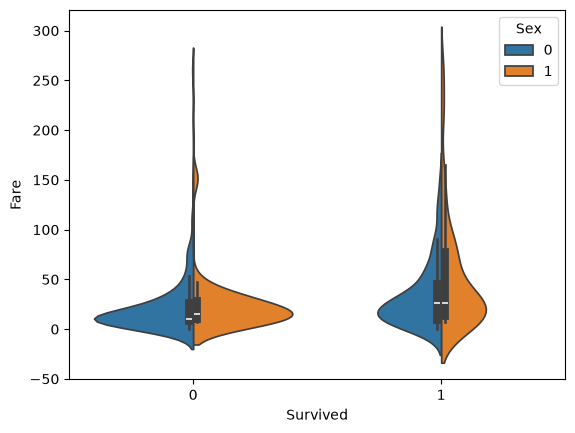

In [152]:
sns.violinplot(df_clean, x="Survived", y= "Fare", hue="Sex", split=True)

Es gibt einige Ausreißer, die den Graphen etwas verzerren, aber man erkennt Ergebnisse. Der durchschnittliche Ticketpreis bei den überlebenden ist nur minimal höher als bei den toten. Es sind deut

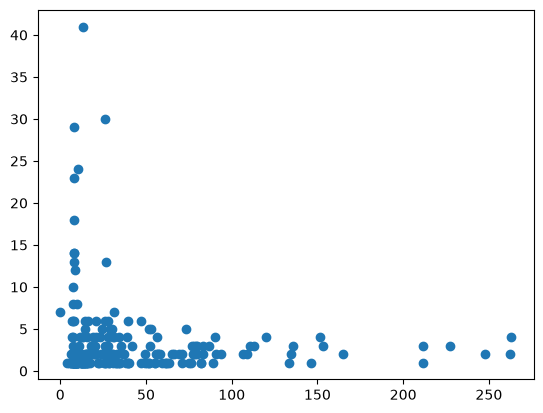

In [153]:
df_fare_counts = df_clean.groupby("Fare", as_index=False).count()
plt.scatter(df_fare_counts["Fare"], df_fare_counts["Survived"])

In [154]:
#totalcount survivors
#irgendwas ist da merkwürdig, müssten mehr sein
df_survived = df_clean[df_clean["Survived"] == 1]#scannt df_clean nach Survived
df_survived_men = len(df_survived[df_survived["Sex"] == 0])##es wird nach Sex sortiert, 0 für male, 1 für female
df_survived_woman = len(df_survived[df_survived["Sex"] == 1])

print("Total Woman Survivors:", df_survived_woman)
print("Total Men Survivors:", df_survived_men)

Total Woman Survivors: 196
Total Men Survivors: 91



 9. df_clean auf Lücken und richtiges Format prüfen:

In [155]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 711 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  711 non-null    int64  
 1   Pclass    711 non-null    int64  
 2   Sex       711 non-null    int64  
 3   Age       711 non-null    float64
 4   SibSp     711 non-null    int64  
 5   Parch     711 non-null    int64  
 6   Fare      711 non-null    float64
 7   FareMode  1 non-null      float64
dtypes: float64(3), int64(5)
memory usage: 50.0 KB


# Model

## RandomForestClassifier

In [156]:
model = RandomForestClassifier()
# X = df_clean[["Age", "Fare", "Pclass", "Sex", "SibSp", ]]
X = df_clean.drop(columns=["Survived"])
X=df_clean.drop(columns=["FareMode"])
y = df_clean["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, )
model.fit(X_train, y_train)

print(
    "Accuracy:", model.score(X_test, y_test), "%"
)

Accuracy: 1.0 %


## SkLearn linear_model

In [157]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import joblib

lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train, y_train)

## Accuracy prüfen
y_pred = lr_model.predict(X_test)
print(
    "Regression Accuracy:",
    accuracy_score(y_test, y_pred),
)
joblib.dump(lr_model, "titanic_logistic_model.pkl")

Regression Accuracy: 1.0


['titanic_logistic_model.pkl']

Liste mit Predictions am Ende:

In [158]:
df_clean["Prediction"] = model.predict(X)
display(df_clean)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FareMode,Prediction
0,0,3,0,22.0,1,0,7.2500,13.0,0
1,1,1,1,38.0,1,0,71.2833,NaN,1
2,1,3,1,26.0,0,0,7.9250,NaN,1
3,1,1,1,35.0,1,0,53.1000,NaN,1
4,0,3,0,35.0,0,0,8.0500,NaN,0
...,...,...,...,...,...,...,...,...,...
885,0,3,1,39.0,0,5,29.1250,NaN,0
886,0,2,0,27.0,0,0,13.0000,NaN,0
887,1,1,1,19.0,0,0,30.0000,NaN,1
889,1,1,0,26.0,0,0,30.0000,NaN,1


# Joblib 
 fürs runterladen und späteres laden des models

In [ ]:
import joblib
##aus der joblib doc

# Save the trained model to a file

joblib.dump(model, "trained_titanic_model.pkl")

# Later, you can load the model using:

# loaded_model = joblib.load(‘trained_model.pkl’)

['trained_titanic_model.pkl']

# Notizen

es gibt keine Nullstellen mehr, es gibt keine duplicates mehr

In [160]:
## Wie kann anhand verschiedener Merkmale herausgefunden werden, ob ein Passagier überlebt?

## Wir wollen eine oder mehrere Eigenschaften angeben und dann die Überlebenschancen des jeweiligen Passagiers berechnen können


##PassengerId = int
##Survived = int, evtl bool? -> wie ist das in python/java
##Pclass = int
##Name= String
##Sex = Str
##Age = int
##SibSp = int
##Parch = int
##Ticket = str
##Fare = int
##Cabin = Str
##Embarked = Str

#df["Age"].head(1) ##head() ist die Zeile, für df[""] einfach Kategorienamen eintragen
#df.shape ##Ist die Anzahl an Zeilen und Spalten
#df.info ##Namen der Spalten
#df.describe ##Kennzahlen der Zahlenspalten
#df.isnull().sum() ##alle Kategorien werden aufgezählt. daneben die Anzahl der leeren Spalten in dieser Kategorie
#(df.isnull().sum() / len(df) * 100).round(1) ##schaut wieviel leere Stellen/Plätze in einer Kategorie vorkommen und rechnet diese dann in Prozentzahlen um: 19.0 sind also 19%Leere Stellen/Plätze
#df["Age"].fillna(df["Age"].median())


##Fehlende Werte:
##Cabin -> kann man rausstreichen, da mehr als drei viertel der Daten fehlen, Versuche der Rekonstruktion könnten also denDatensatz verfäschen oder beschädigen
##Age -> evtl Durchschnittsalter der Passagiere errechnen und dadurch ersetzen, knapp unter ein Viertel der Daten ist verloren gegangen.
##Embarked -> kann man easy rausnehmen, es fehlen nur ca 2 Einträge